In [1]:
import os

try:
    import google.colab
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/recsys-project/data'
except ImportError:
    DATA_DIR = './data'

ratings_path = os.path.join(DATA_DIR, 'ratings.dat')
movies_path = os.path.join(DATA_DIR, 'movies.dat')
users_path = os.path.join(DATA_DIR, 'users.dat')

Mounted at /content/drive


In [2]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn
# remember run this section if you haven't install packages

In [3]:
import pandas as pd

# load ratings.dat: user, item, rating, timestamp
ratings = pd.read_csv(
    ratings_path, sep='::', header=None,
    names=['user_id', 'item_id', 'rating', 'timestamp'],
    engine='python'
)
print(ratings.head())
print()

# load movies.dat: item, title, genres
movies = pd.read_csv(
    movies_path, sep='::', header=None,
    names=['item_id', 'title', 'genres'],
    engine='python', encoding='latin-1'
)
print(movies.head())
print()

# load users.dat: user, gender, age, occupation, zip
users = pd.read_csv(
    users_path, sep='::', header=None,
    names=['user_id', 'gender', 'age', 'occupation', 'zip_code'],
    engine='python'
)
print(users.head())

print()
print(f"Loaded {len(ratings)} ratings, {len(movies)} movies, {len(users)} users.")

   user_id  item_id  rating  timestamp
0        1     1193       5  978300760
1        1      661       3  978302109
2        1      914       3  978301968
3        1     3408       4  978300275
4        1     2355       5  978824291

   item_id                               title                        genres
0        1                    Toy Story (1995)   Animation|Children's|Comedy
1        2                      Jumanji (1995)  Adventure|Children's|Fantasy
2        3             Grumpier Old Men (1995)                Comedy|Romance
3        4            Waiting to Exhale (1995)                  Comedy|Drama
4        5  Father of the Bride Part II (1995)                        Comedy

   user_id gender  age  occupation zip_code
0        1      F    1          10    48067
1        2      M   56          16    70072
2        3      M   25          15    55117
3        4      M   45           7    02460
4        5      M   25          20    55455

Loaded 1000209 ratings, 3883 movies, 

# PART 1


## Analyze the data characterization


In [ ]:
# basic information got user, items, ratings and matrix density
n_users = ratings['user_id'].nunique()
n_items = ratings['item_id'].nunique()
n_interactions = len(ratings)
density = n_interactions / (n_users * n_items)


print("Dataset Characterization Summary:")
print(f"- Total Users: {n_users}")
print(f"- Total Items (Movies): {n_items}")
print(f"- Total Interactions (Ratings): {n_interactions}")
print(f"- Matrix Density: {density:.6f} ({density * 100:.4f}%)")

Dataset Characterization Summary:
- Total Users: 6040
- Total Items (Movies): 3706
- Total Interactions (Ratings): 1000209
- Matrix Density: 0.044684 (4.4684%)


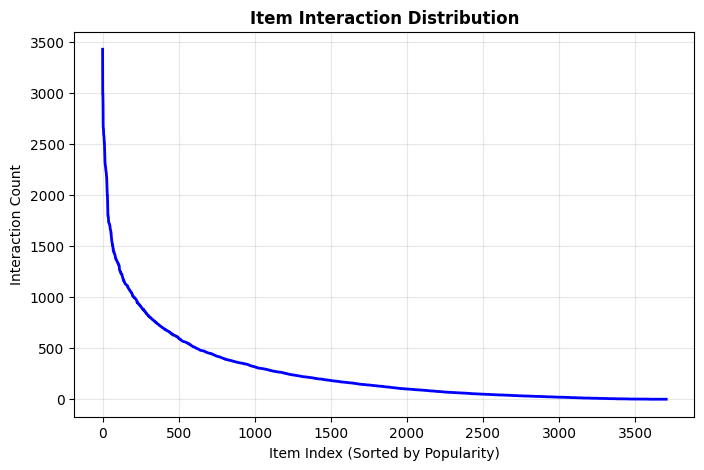

In [ ]:
# Item interaction distribution
import numpy as np
import matplotlib.pyplot as plt


item_counts = ratings['item_id'].value_counts().values
item_counts_sorted = np.sort(item_counts)[::-1]

plt.figure(figsize=(8, 5))
plt.plot(item_counts_sorted, color='b', linewidth=2)
plt.title('Item Interaction Distribution',
          fontsize=12, fontweight='bold')
plt.xlabel('Item Index (Sorted by Popularity)')
plt.ylabel('Interaction Count')
plt.grid(alpha=0.3)

plt.savefig('/content/drive/MyDrive/recsys-project/figure/Item Interaction Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

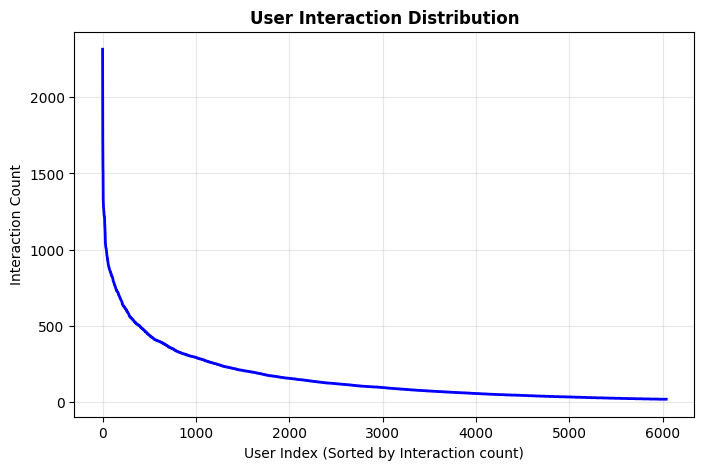

In [ ]:
# User Interaction Distribution
user_counts = ratings['user_id'].value_counts().values
user_counts_sorted = np.sort(user_counts)[::-1]


plt.figure(figsize=(8, 5))
plt.plot(user_counts, color='b', linewidth=2)

plt.title('User Interaction Distribution',
          fontsize=12, fontweight='bold')
plt.xlabel('User Index (Sorted by Interaction count)')
plt.ylabel('Interaction Count')
plt.grid(alpha=0.3)

plt.savefig('/content/drive/MyDrive/recsys-project/figure/User Interaction Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_3325/1061845512.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


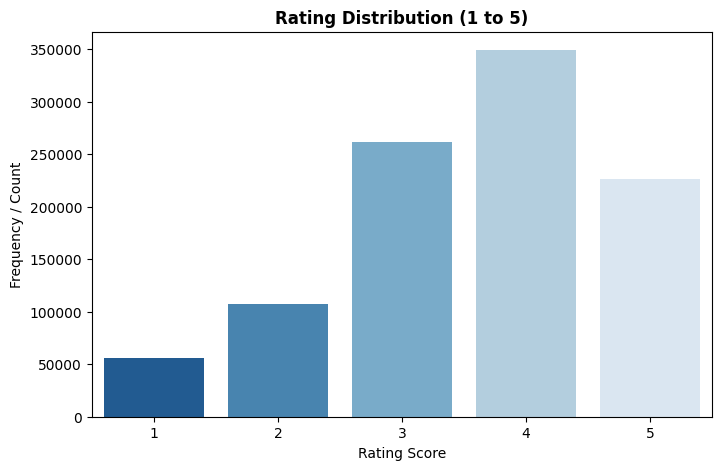

In [ ]:
# Ratings Distribution
import seaborn as sns

plt.figure(figsize=(8, 5))
ax = plt.gca()

sns.countplot(
    x='rating',
    data=ratings,
    ax=ax,
    palette='Blues_r'
)

ax.set_title('Rating Distribution (1 to 5)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Rating Score')
ax.set_ylabel('Frequency / Count')

# plt.savefig('/content/drive/MyDrive/recsys-project/figure/Rating Distribution (1 to 5).png', dpi=300, bbox_inches='tight')
plt.show()

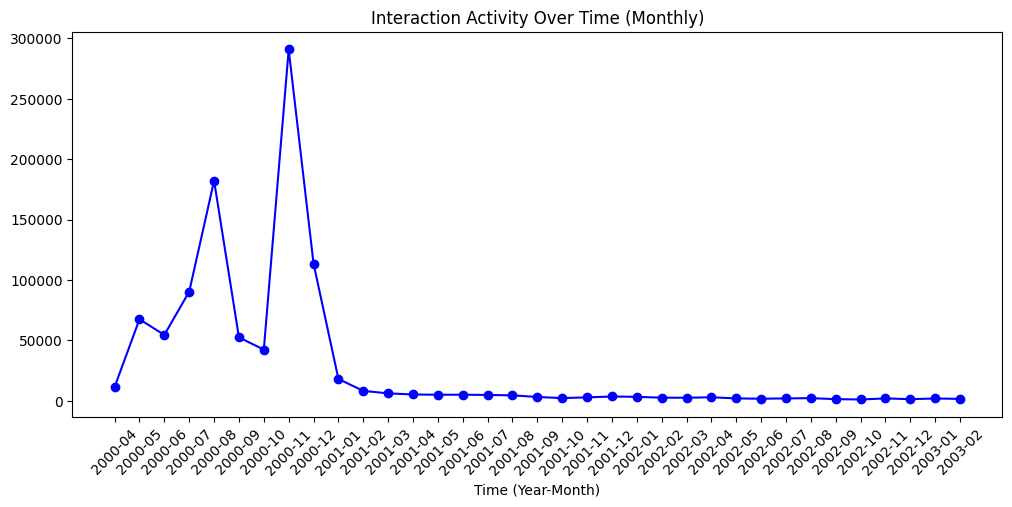

In [ ]:
# Time Span & Activity Distribution
ratings['datetime'] = pd.to_datetime(ratings['timestamp'], unit='s')
ratings['date'] = ratings['datetime'].dt.to_period('M').astype(str)

activity_over_time = ratings.groupby('date').size()

plt.figure(figsize=(12, 5))
plt.xticks(rotation=45)
ax = plt.gca()

ax.plot(
    activity_over_time.index,
    activity_over_time.values,
    marker='o',
    color='b',
    linestyle='-'
)

ax.set_title('Interaction Activity Over Time (Monthly)')
ax.set_xlabel('Time (Year-Month)')

plt.xticks(rotation=45)

# plt.savefig('/content/drive/MyDrive/recsys-project/figure/Interaction Activity Over Time (Monthly).png', dpi=300, bbox_inches='tight')
plt.show()

## Train/validation/test split
To decide the split method, we need to check if the popularity has strong correlation with time. Here we check if the top-k most popular movies changed over time.

In [5]:
ratings_sorted = ratings.sort_values('timestamp')

mid = len(ratings_sorted) // 2

early_data = ratings_sorted.iloc[:mid]
late_data = ratings_sorted.iloc[mid:]

K = 10

early_top_k = set(
    early_data['item_id'].value_counts().head(K).index
)

late_top_k = set(
    late_data['item_id'].value_counts().head(K).index
)

overlap = len(early_top_k & late_top_k)
overlap_ratio = overlap / K

print("Early Top 10:", early_top_k)
print("Late Top 10:", late_top_k)
print(f"Common items: {overlap}")
print(f"Top-10 overlap ratio: {overlap_ratio:.2%}")

Early Top 10: {608, 260, 2858, 2571, 1196, 2762, 2028, 593, 1270, 1210}
Late Top 10: {480, 260, 2858, 1196, 589, 2028, 1580, 110, 593, 1210}
Common items: 6
Top-10 overlap ratio: 60.00%


Thus, we decide to use the  recent window for most popular baseline, and split the data by time.

In [6]:
ratings = ratings.sort_values('timestamp')

train_ratio, val_ratio = 0.7, 0.15
n = len(ratings)
train_end = int(n * train_ratio)
val_end = int(n * (train_ratio + val_ratio))

train_set = ratings.iloc[:train_end]
val_set = ratings.iloc[train_end:val_end]
test_set = ratings.iloc[val_end:]

print(f"Train size: {len(train_set)}, Val size: {len(val_set)}, Test size: {len(test_set)}")

Train size: 700146, Val size: 150031, Test size: 150032


In [7]:
datasets = {
    'Training': train_set,
    'Validation': val_set,
    'Test': test_set
}

for name, df in datasets.items():
    start_time = pd.to_datetime(
        df['timestamp'].min(), unit='s', utc=True
    )

    end_time = pd.to_datetime(
        df['timestamp'].max(), unit='s', utc=True
    )

    print(f"{name} set:")
    print(f"  Start: {start_time}")
    print(f"  End:   {end_time}")
    print(f"  Interactions: {len(df)}")
    print()

Training set:
  Start: 2000-04-25 23:05:32+00:00
  End:   2000-11-22 03:06:26+00:00
  Interactions: 700146

Validation set:
  Start: 2000-11-22 03:06:26+00:00
  End:   2000-12-10 04:20:42+00:00
  Interactions: 150031

Test set:
  Start: 2000-12-10 04:20:54+00:00
  End:   2003-02-28 17:49:50+00:00
  Interactions: 150032



## Metrics

In [28]:
def evaluate_model(recommend_func, relevant_items, catalogue, k=10):

  precisions = []
  recalls = []
  ndcg_scores = []
  recommended_items = set()

  for user_id, relevant in relevant_items.items():

    recommendations = recommend_func(user_id, top_k=k)
    recommendations = recommendations[:k]

    recommended_items.update(recommendations)

    hits = len(set(recommendations) & relevant)

    # Precision@K
    precisions.append(hits / k)

    # Recall@K
    recalls.append(hits / len(relevant))

    # NDCG@K
    dcg = sum(
          1 / np.log2(rank + 1)
          for rank, item_id in enumerate(recommendations, start=1)
          if item_id in relevant)

    ideal_hits = min(len(relevant), k)

    idcg = sum(
          1 / np.log2(rank + 1)
          for rank in range(1, ideal_hits + 1))

    ndcg_scores.append(dcg / idcg if idcg > 0 else 0.0)

  # Catalogue Coverage
  coverage = len(recommended_items) / len(catalogue)

  return {
      'Precision@10': np.mean(precisions),
      'Recall@10': np.mean(recalls),
      'NDCG@10': np.mean(ndcg_scores),
      'Catalogue Coverage': coverage}

## Baselines - setup

In [9]:
item_user_matrix = train_set.pivot_table(
    index='item_id',
    columns='user_id',
    values='rating',
    fill_value=0
)

item_ids = item_user_matrix.index.to_numpy()
catalogue = set(item_ids)

# Relevant items in validation and test sets
relevant_val = (
    val_set[val_set['rating'] >= 4]
    .groupby('user_id')['item_id']
    .apply(set)
    .to_dict()
)

relevant_test = (
    test_set[test_set['rating'] >= 4]
    .groupby('user_id')['item_id']
    .apply(set)
    .to_dict()
)

user_seen_items = {
    user_id: set(group['item_id'])
    for user_id, group in train_set.groupby('user_id')
}

user_ratings = {
    user_id: dict(zip(group['item_id'], group['rating']))
    for user_id, group in train_set.groupby('user_id')
}

## Baselines - Item Based kNN

In [ ]:
from sklearn.neighbors import NearestNeighbors

def item_based_knn(n_neighbors, similarity_measure):

  n = min(n_neighbors + 1, len(item_ids))

  knn_model = NearestNeighbors(
        metric=similarity_measure,
        algorithm='brute',
        n_neighbors=n
  )

  knn_model.fit(item_user_matrix)

  distances, indices = knn_model.kneighbors(item_user_matrix)

  if similarity_measure in ['cosine', 'correlation']:
    similarities = 1 - distances

  elif similarity_measure == 'euclidean':
    similarities = 1 / (1 + distances)

  item_neighbors = {}
  for i, item_id in enumerate(item_ids):
    neighbors = []

    for j, sim in zip(indices[i], similarities[i]):
      neighbor_id = item_ids[j]

      if neighbor_id != item_id:
        neighbors.append((neighbor_id, sim))

    item_neighbors[item_id] = neighbors

  return item_neighbors


In [ ]:
def recommend_item_based_knn(user_id, item_neighbors, top_k):

  seen_items = user_seen_items.get(user_id, set())
  ratings = user_ratings.get(user_id, {})

  scores = {}

  for item_id, rating in ratings.items():
    if rating < 4:
      continue

    for neighbor_id, similarity in item_neighbors.get(item_id, []):
      if neighbor_id in seen_items:
        continue

      scores[neighbor_id] = (
        scores.get(neighbor_id, 0)
        + similarity * rating)

  ranked_items = sorted(
    scores.items(),
    key=lambda x: x[1],
    reverse=True)

  return [item for item, score in ranked_items[:top_k]]


In [ ]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd

k_values = [1, 5, 50, 150, 200]
similarity_measures = ['cosine', 'euclidean', 'correlation']

results = []

for k in k_values:
  for sm in similarity_measures:
    item_neighbors = item_based_knn(k, sm)

    def recommend_func(user_id, top_k=10):
      return recommend_item_based_knn(user_id, item_neighbors, top_k)

    metrics = evaluate_model(
            recommend_func,
            relevant_val,
            catalogue)

    results.append({
            'n_neighbors': k,
            'similarity measure': sm,
            **metrics})

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

display(results_df.round(4))

,n_neighbors,similarity measure,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,1,cosine,0.0407,0.0164,0.0481,0.1431
1,1,euclidean,0.0064,0.0022,0.0060,0.2684
2,1,correlation,0.0343,0.0117,0.0387,0.1621
3,5,cosine,0.0531,0.0183,0.0579,0.1159
4,5,euclidean,0.0052,0.0018,0.0053,0.2772
5,5,correlation,0.0414,0.0140,0.0453,0.1495
6,50,cosine,0.0578,0.0181,0.0633,0.0735
7,50,euclidean,0.0029,0.0008,0.0032,0.1905
8,50,correlation,0.0404,0.0143,0.0444,0.1497
9,150,cosine,0.0600,0.0182,0.0659,0.0606


## Baseline - Most Popular

In [ ]:
def recommend_most_popular(user_id, popularity, top_k=10):

  seen_items = user_seen_items.get(user_id, set())

  recommendations = [
    item_id for item_id in popularity.index
    if item_id not in seen_items
    ]

  return recommendations[:top_k]

In [ ]:
# Tune the most popular model with different popularity variants
popularity_variants = ['all_ratings', 'positive_ratings']
results = []

for variant in popularity_variants:

  if variant == 'all_ratings':
    item_popularity = train_set['item_id'].value_counts()

  elif variant == 'positive_ratings':
    item_popularity = (
      train_set[train_set['rating'] >= 4]['item_id'].value_counts())

  popular_items = item_popularity.index.tolist()

  def recommend_func(user_id, top_k=10, popularity=item_popularity):
    return recommend_most_popular(user_id, popularity, top_k)

  metrics = evaluate_model(
        recommend_func,
        relevant_val,
        catalogue
    )

  results.append({
    'Popularity variant': variant,
    **metrics})

results_df = pd.DataFrame(results)

popular_results_df = pd.DataFrame(results)

display(popular_results_df.round(4))


,Popularity variant,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,all_ratings,0.2753,0.0608,0.2957,0.0325
1,positive_ratings,0.2781,0.0618,0.2982,0.0289


Now we decide to choose k=150, measure='cosine' for item based kNN, and positive rating for most popular. Next we will examine the model with test set.

In [ ]:
# Set up dataset
final_neighbors = item_based_knn(
  n_neighbors=150,
  similarity_measure='cosine'
)

def knn_final(user_id, top_k=10):
  return recommend_item_based_knn(user_id, final_neighbors, top_k)

positive_popularity = (
  train_set[train_set['rating'] >= 4]['item_id'].value_counts()
)

def popular_final(user_id, top_k=10):
  return recommend_most_popular(user_id, positive_popularity, top_k)


final_models = {
  'Item-based KNN (Cosine, k=150)': knn_final,
  'Most Popular (Positive ratings)': popular_final
}


In [ ]:
test_results = []

for model_name, recommend_func in final_models.items():

  metrics = evaluate_model(
    recommend_func,
    relevant_test,
    catalogue
    )

  test_results.append({
    'Model': model_name,
    **metrics
  })


test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Model,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,"Item-based KNN (Cosine, k=150)",0.1113,0.0309,0.1234,0.0718
1,Most Popular (Positive ratings),0.2199,0.0518,0.2332,0.0333


# Part 2

## Latent-factor CF with bias and ALS gradient used

In [10]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

In [11]:
# ALS - One-time data preparation

def prepare_als_data(train_data):

    user_ids = train_data["user_id"].unique()
    item_ids = train_data["item_id"].unique()

    user_to_idx = {
        user_id: idx for idx, user_id in enumerate(user_ids)
    }
    item_to_idx = {
        item_id: idx for idx, item_id in enumerate(item_ids)
    }

    train_users = train_data["user_id"].map(
        user_to_idx
    ).to_numpy(dtype=np.int32)

    train_items = train_data["item_id"].map(
        item_to_idx
    ).to_numpy(dtype=np.int32)

    train_ratings = train_data["rating"].to_numpy(dtype=np.float64)

    # Sort observations once and split their positions into user groups
    user_order = np.argsort(train_users)
    user_counts = np.bincount(
        train_users, minlength=len(user_ids)
    )
    user_groups = np.split(
        user_order, np.cumsum(user_counts)[:-1]
    )

    # Sort observations once and split their positions into item groups
    item_order = np.argsort(train_items)
    item_counts = np.bincount(
        train_items, minlength=len(item_ids)
    )
    item_groups = np.split(
        item_order, np.cumsum(item_counts)[:-1]
    )

    # Items already rated by each user (for recommendation filtering)
    train_seen_items = (
        train_data.groupby("user_id")["item_id"]
        .apply(set)
        .to_dict()
    )

    # Popularity fallback for users not present in the training data
    popular_items = (
        train_data[train_data["rating"] >= 4]["item_id"]
        .value_counts()
        .index.tolist()
    )

    # Fixed global mean, calculated using training ratings only
    global_mean = float(np.mean(train_ratings))

    return {
        "user_ids": user_ids,
        "item_ids": item_ids,
        "user_to_idx": user_to_idx,
        "item_to_idx": item_to_idx,
        "train_users": train_users,
        "train_items": train_items,
        "train_ratings": train_ratings,
        "user_groups": user_groups,
        "item_groups": item_groups,
        "train_seen_items": train_seen_items,
        "popular_items": popular_items,
        "global_mean": global_mean
    }


als_data = prepare_als_data(train_set)

print(f"Users: {len(als_data['user_ids'])}")
print(f"Items: {len(als_data['item_ids'])}")
print(f"Training ratings: {len(als_data['train_ratings'])}")
print(f"Global mean rating: {als_data['global_mean']:.4f}")


Users: 4870
Items: 3633
Training ratings: 700146
Global mean rating: 3.6019


In [12]:
class BiasedALS:
    """Explicit-feedback ALS with global, user, and item biases."""

    def __init__(
        self,
        als_data,
        n_factors=50,
        regularization=0.1,
        n_iterations=15,
        random_state=SEED,
        patience=3, min_delta=0.0001
        # allow the objective shows no improvement in 3 epoch, and the minimum delta for new
        # objective should be at least 0.0001.

    ):
        self.data = als_data
        self.n_factors = n_factors
        self.regularization = regularization
        self.n_iterations = n_iterations
        self.random_state = random_state

        self.patience = patience
        self.min_delta = min_delta

        self.P = None
        self.Q = None
        self.user_bias = None
        self.item_bias = None
        self.history = []

    def _update_user_factors_and_biases(self):
        """Update each p_u and b_u while Q and item biases are fixed."""

        reg_identity = self.regularization * self.identity
        ratings = self.data["train_ratings"]
        train_items = self.data["train_items"]

        for user_idx, obs_indices in enumerate(self.data["user_groups"]):
            item_indices = train_items[obs_indices]
            ratings_u = ratings[obs_indices]
            Q_u = self.Q[item_indices]

            # Residual after removing global mean and current biases
            residual = (
                ratings_u
                - self.data["global_mean"]
                - self.user_bias[user_idx]
                - self.item_bias[item_indices]
            )

            # Conditional least-squares update for p_u
            A = Q_u.T @ Q_u + reg_identity
            b = Q_u.T @ residual
            self.P[user_idx] = np.linalg.solve(A, b)

            # Conditional least-squares update for b_u
            factor_predictions = Q_u @ self.P[user_idx]
            bias_residual = (
                ratings_u
                - self.data["global_mean"]
                - self.item_bias[item_indices]
                - factor_predictions
            )

            self.user_bias[user_idx] = (
                np.sum(bias_residual)
                / (len(obs_indices) + self.regularization)
            )

    def _update_item_factors_and_biases(self):
        """Update each q_i and b_i while P and user biases are fixed."""

        reg_identity = self.regularization * self.identity
        ratings = self.data["train_ratings"]
        train_users = self.data["train_users"]

        for item_idx, obs_indices in enumerate(self.data["item_groups"]):
            user_indices = train_users[obs_indices]
            ratings_i = ratings[obs_indices]
            P_i = self.P[user_indices]

            # Residual after removing global mean and current biases
            residual = (
                ratings_i
                - self.data["global_mean"]
                - self.user_bias[user_indices]
                - self.item_bias[item_idx]
            )

            # Conditional least-squares update for q_i
            A = P_i.T @ P_i + reg_identity
            b = P_i.T @ residual
            self.Q[item_idx] = np.linalg.solve(A, b)

            # Conditional least-squares update for b_i
            factor_predictions = P_i @ self.Q[item_idx]
            bias_residual = (
                ratings_i
                - self.data["global_mean"]
                - self.user_bias[user_indices]
                - factor_predictions
            )

            self.item_bias[item_idx] = (
                np.sum(bias_residual)
                / (len(obs_indices) + self.regularization)
            )

    def calculate_objective(self):
        """Calculate the exact regularized objective used for ALS fitting."""

        data = self.data

        predictions = (
            data["global_mean"]
            + self.user_bias[data["train_users"]]
            + self.item_bias[data["train_items"]]
            + np.sum(
                self.P[data["train_users"]]
                * self.Q[data["train_items"]],
                axis=1
            )
        )

        squared_error = np.sum(
            (data["train_ratings"] - predictions) ** 2
        )

        regularization_loss = self.regularization * (
            np.sum(self.P ** 2)
            + np.sum(self.Q ** 2)
            + np.sum(self.user_bias ** 2)
            + np.sum(self.item_bias ** 2)
        )

        return float(squared_error + regularization_loss)

    def recommend(self, user_id, top_k=10):
        data = self.data

        # Popularity fallback for users not present in training
        if user_id not in data["user_to_idx"]:
            seen = data["train_seen_items"].get(user_id, set())
            return [
                item_id for item_id in data["popular_items"]
                if item_id not in seen
            ][:top_k]

        user_idx = data["user_to_idx"][user_id]

        # Predicted rating: mu + user bias + item bias + p_u dot q_i
        scores = (
            data["global_mean"]
            + self.user_bias[user_idx]
            + self.item_bias
            + self.Q @ self.P[user_idx]
        )

        # Do not recommend movies already rated in the training set
        seen = data["train_seen_items"].get(user_id, set())
        seen_indices = [
            data["item_to_idx"][item_id]
            for item_id in seen
            if item_id in data["item_to_idx"]
        ]
        scores[seen_indices] = -np.inf

        k = min(top_k, len(scores))
        if k == 0:
            return []

        top_indices = np.argpartition(scores, -k)[-k:]
        top_indices = top_indices[
            np.argsort(scores[top_indices])[::-1]
        ]

        return [
            data["item_ids"][idx] for idx in top_indices
        ]

    def fit(self, validation_relevance, catalogue, evaluator):
        rng = np.random.default_rng(self.random_state)

        n_users = len(self.data["user_ids"])
        n_items = len(self.data["item_ids"])

        # Initialize latent factors; initialize biases at zero
        self.P = rng.normal(
            0, 0.1, size=(n_users, self.n_factors)
        )
        self.Q = rng.normal(
            0, 0.1, size=(n_items, self.n_factors)
        )
        self.user_bias = np.zeros(n_users, dtype=np.float64)
        self.item_bias = np.zeros(n_items, dtype=np.float64)

        self.identity = np.eye(self.n_factors)

        self.history = []
        self.best_iteration = None
        self.best_metrics = None

        best_ndcg = -np.inf
        epochs_without_improvement = 0

        best_P = None
        best_Q = None
        best_user_bias = None
        best_item_bias = None


        for iteration in range(1, self.n_iterations + 1):

            self._update_user_factors_and_biases()
            self._update_item_factors_and_biases()

            objective = self.calculate_objective()

            metrics = evaluator(
                self.recommend,
                validation_relevance,
                catalogue
            )

            self.history.append({
                "Iteration": iteration,
                "Objective": objective,
                **metrics
            })

            current_ndcg = metrics["NDCG@10"]

            if (
                np.isfinite(current_ndcg)
                and current_ndcg > best_ndcg + self.min_delta
            ):
                # Update the best validation NDCG
                best_ndcg = current_ndcg

                self.best_iteration = iteration
                self.best_metrics = metrics.copy()

                # Save the best model parameters
                best_P = self.P.copy()
                best_Q = self.Q.copy()
                best_user_bias = self.user_bias.copy()
                best_item_bias = self.item_bias.copy()

                epochs_without_improvement = 0

            else:
                epochs_without_improvement += 1

            # Early stopping
            if epochs_without_improvement >= self.patience:
                print(
                    f"Early stopping at iteration {iteration}: "
                    f"Validation NDCG@10 did not improve for "
                    f"{self.patience} consecutive epochs."
                )
                break

        # Restore the minimum-objective checkpoint
        self.P = best_P
        self.Q = best_Q
        self.user_bias = best_user_bias
        self.item_bias = best_item_bias
        self.objective = objective

        self.best_ndcg = self.best_metrics["NDCG@10"]

        return self


In [62]:
param_grid = {
    "n_factors": [20, 50, 70, 100, 150],
    "regularization": [0.5]
}

als_max_iter = 50
als_random_state = SEED

In [63]:
# ALS - Hyperparameter tuning using nested for loops

als_iteration_results = []
als_results = []

best_als_model = None
best_als_ndcg = -np.inf
experiment = 0

for n_factors in param_grid["n_factors"]:
    for regularization in param_grid["regularization"]:

        experiment += 1

        print(
            f"\\nExperiment {experiment}: "
            f"n_factors={n_factors}, "
            f"regularization={regularization}"
        )

        als_model = BiasedALS(
            als_data=als_data,
            n_factors=n_factors,
            regularization=regularization,
            n_iterations=50,
            random_state=als_random_state + experiment
        )

        als_model.fit(
            validation_relevance=relevant_val,
            catalogue=catalogue,
            evaluator=evaluate_model
        )

        # Save all epoch-level results
        for row in als_model.history:
            als_iteration_results.append({
                "n_factors": n_factors,
                "regularization": regularization,
                **row
            })

        # Save the minimum-objective epoch for this configuration
        als_results.append({
            "n_factors": n_factors,
            "regularization": regularization,
            "Best iteration": als_model.best_iteration,
            "Best objective": als_model.objective,
            **als_model.best_metrics
        })


als_iteration_results_df = pd.DataFrame(als_iteration_results)
als_results_df = pd.DataFrame(als_results)

print("\\nBest epoch for each parameter combination:")
display(
    als_results_df
    .sort_values(
        by=["n_factors", "regularization"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
    .round(4)
)

print("\\nAll epoch-level results:")
display(
    als_iteration_results_df
    .sort_values(["n_factors", "regularization", "Iteration"])
    .reset_index(drop=True)
    .round(4)
)

\nExperiment 1: n_factors=20, regularization=0.5
Early stopping at iteration 26: Validation NDCG@10 did not improve for 3 consecutive epochs.
\nExperiment 2: n_factors=50, regularization=0.5
Early stopping at iteration 36: Validation NDCG@10 did not improve for 3 consecutive epochs.
\nExperiment 3: n_factors=70, regularization=0.5
Early stopping at iteration 30: Validation NDCG@10 did not improve for 3 consecutive epochs.
\nExperiment 4: n_factors=100, regularization=0.5
Early stopping at iteration 20: Validation NDCG@10 did not improve for 3 consecutive epochs.
\nExperiment 5: n_factors=150, regularization=0.5
Early stopping at iteration 35: Validation NDCG@10 did not improve for 3 consecutive epochs.
\nBest epoch for each parameter combination:


,n_factors,regularization,Best iteration,Best objective,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,20,0.5,23,314263.1936,0.2300,0.0444,0.2425,0.2766
1,50,0.5,33,176403.9824,0.2318,0.0450,0.2450,0.3457
2,70,0.5,27,124911.2333,0.2329,0.0454,0.2464,0.3589
3,100,0.5,17,79888.5747,0.2334,0.0459,0.2470,0.3554
4,150,0.5,32,38128.6584,0.2421,0.0471,0.2564,0.3064


\nAll epoch-level results:


,n_factors,regularization,Iteration,Objective,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,20,0.5,1,526203.5937,0.2210,0.0418,0.2337,0.1979
1,20,0.5,2,403801.0877,0.2221,0.0422,0.2347,0.2395
2,20,0.5,3,371170.4387,0.2227,0.0421,0.2353,0.2549
3,20,0.5,4,354601.8963,0.2230,0.0421,0.2358,0.2642
4,20,0.5,5,344669.2437,0.2237,0.0425,0.2364,0.2626
...,...,...,...,...,...,...,...,...
142,150,0.5,31,38844.6579,0.2419,0.0471,0.2562,0.3069
143,150,0.5,32,38649.6763,0.2421,0.0471,0.2564,0.3064
144,150,0.5,33,38466.0171,0.2422,0.0472,0.2565,0.3044
145,150,0.5,34,38292.6461,0.2424,0.0473,0.2565,0.3036


### chosen ALS model

In [75]:
choosen_als_model = BiasedALS(
    als_data=als_data,
    n_factors=150,
    regularization=0.5,
    n_iterations=32,
    random_state=SEED)

## Latent factor CF with bias and SGD gradient used

In [14]:
class BiasedSGD:
    """Explicit-feedback SGD with global, user, and item biases."""

    def __init__(
        self,
        sgd_data,
        n_factors=50,
        regularization=0.1,
        learning_rate=0.005,
        n_iterations=15,
        random_state=SEED,
        patience=3, min_delta=0.0001
        # allow the objective shows no improvement in 3 epoch, and the minimum delta for new
        # objective should be at least 0.0001.

    ):
        self.data = sgd_data
        self.n_factors = n_factors
        self.regularization = regularization
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.random_state = random_state

        self.patience = patience
        self.min_delta = min_delta

        self.P = None
        self.Q = None
        self.user_bias = None
        self.item_bias = None
        self.history = []


    def calculate_objective(self):
        """Calculate the exact regularized objective used for SGD fitting."""

        data = self.data

        predictions = (
            data["global_mean"]
            + self.user_bias[data["train_users"]]
            + self.item_bias[data["train_items"]]
            + np.sum(
                self.P[data["train_users"]]
                * self.Q[data["train_items"]],
                axis=1
            )
        )

        squared_error = np.sum(
            (data["train_ratings"] - predictions) ** 2
        )

        regularization_loss = self.regularization * (
            np.sum(self.P ** 2)
            + np.sum(self.Q ** 2)
            + np.sum(self.user_bias ** 2)
            + np.sum(self.item_bias ** 2)
        )

        return float(squared_error + regularization_loss)


    def _update_parameters(self, observation_indices):
        """Update parameters using individual rating observations."""

        ratings = self.data["train_ratings"]
        train_users = self.data["train_users"]
        train_items = self.data["train_items"]

        lr = self.learning_rate
        reg = self.regularization

        for obs_idx in observation_indices:

            user_idx = train_users[obs_idx]
            item_idx = train_items[obs_idx]
            rating = ratings[obs_idx]

            # Current prediction
            prediction = (
                self.data["global_mean"]
                + self.user_bias[user_idx]
                + self.item_bias[item_idx]
                + np.dot(
                    self.P[user_idx],
                    self.Q[item_idx]
                )
            )

            error = rating - prediction

            # Save old latent factors before updating
            old_p = self.P[user_idx].copy()
            old_q = self.Q[item_idx].copy()

            # Update user and item biases
            self.user_bias[user_idx] += (
                lr * (error - reg * self.user_bias[user_idx])
            )

            self.item_bias[item_idx] += (
                lr * (error - reg * self.item_bias[item_idx])
            )

            # Update user and item latent factors
            self.P[user_idx] += (
                lr * (error * old_q - reg * old_p)
            )

            self.Q[item_idx] += (
                lr * (error * old_p - reg * old_q)
            )

    def recommend(self, user_id, top_k=10):
        data = self.data

        # Popularity fallback for users not present in training
        if user_id not in data["user_to_idx"]:
            seen = data["train_seen_items"].get(user_id, set())
            return [
                item_id for item_id in data["popular_items"]
                if item_id not in seen
            ][:top_k]

        user_idx = data["user_to_idx"][user_id]

        # Predicted rating: mu + user bias + item bias + p_u dot q_i
        scores = (
            data["global_mean"]
            + self.user_bias[user_idx]
            + self.item_bias
            + self.Q @ self.P[user_idx]
        )

        # Do not recommend movies already rated in the training set
        seen = data["train_seen_items"].get(user_id, set())
        seen_indices = [
            data["item_to_idx"][item_id]
            for item_id in seen
            if item_id in data["item_to_idx"]
        ]
        scores[seen_indices] = -np.inf

        k = min(top_k, len(scores))
        if k == 0:
            return []

        top_indices = np.argpartition(scores, -k)[-k:]
        top_indices = top_indices[
            np.argsort(scores[top_indices])[::-1]
        ]

        return [
            data["item_ids"][idx] for idx in top_indices
        ]

    def fit(self, validation_relevance, catalogue, evaluator):
        rng = np.random.default_rng(self.random_state)

        n_users = len(self.data["user_ids"])
        n_items = len(self.data["item_ids"])
        n_ratings = len(self.data["train_ratings"])

        # Initialize latent factors; initialize biases at zero
        self.P = rng.normal(
            0, 0.1, size=(n_users, self.n_factors)
        )
        self.Q = rng.normal(
            0, 0.1, size=(n_items, self.n_factors)
        )
        self.user_bias = np.zeros(n_users, dtype=np.float64)
        self.item_bias = np.zeros(n_items, dtype=np.float64)

        self.history = []
        self.best_iteration = None
        self.best_metrics = None

        best_ndcg = -np.inf
        epochs_without_improvement = 0

        best_P = None
        best_Q = None
        best_user_bias = None
        best_item_bias = None


        for iteration in range(1, self.n_iterations + 1):
            observation_indices = rng.permutation(n_ratings)

            self._update_parameters(observation_indices)

            objective = self.calculate_objective()

            metrics = evaluator(
                self.recommend,
                validation_relevance,
                catalogue
            )

            self.history.append({
                "Iteration": iteration,
                "Objective": objective,
                **metrics
            })

            current_ndcg = metrics["NDCG@10"]

            if (
                np.isfinite(current_ndcg)
                and current_ndcg > best_ndcg + self.min_delta
            ):
                # Update the best validation NDCG
                best_ndcg = current_ndcg

                self.best_iteration = iteration
                self.best_metrics = metrics.copy()

                # Save the best model parameters
                best_P = self.P.copy()
                best_Q = self.Q.copy()
                best_user_bias = self.user_bias.copy()
                best_item_bias = self.item_bias.copy()

                epochs_without_improvement = 0

            else:
                epochs_without_improvement += 1

            # Early stopping
            if epochs_without_improvement >= self.patience:
                print(
                    f"Early stopping at iteration {iteration}: "
                    f"Validation NDCG@10 did not improve for "
                    f"{self.patience} consecutive epochs."
                )
                break

        # Restore the minimum-objective checkpoint
        self.P = best_P
        self.Q = best_Q
        self.user_bias = best_user_bias
        self.item_bias = best_item_bias
        self.objective = objective

        self.best_ndcg = self.best_metrics["NDCG@10"]

        return self


In [56]:
# SGD - Hyperparameter tuning

sgd_param_grid = {
    "n_factors": [150],
    "regularization": [0.000001],
    "learning_rate": [1e-8]
}

sgd_max_iter = 15
sgd_random_state = SEED

In [57]:
# SGD - Hyperparameter tuning using nested for loops

sgd_iteration_results = []
sgd_results = []

best_sgd_model = None
best_sgd_ndcg = -np.inf

experiment = 0

for n_factors in sgd_param_grid["n_factors"]:
    for regularization in sgd_param_grid["regularization"]:
        for learning_rate in sgd_param_grid["learning_rate"]:

            experiment += 1

            print(
                f"\nExperiment {experiment}: "
                f"n_factors={n_factors}, "
                f"regularization={regularization}, "
                f"learning_rate={learning_rate}"
            )

            sgd_model = BiasedSGD(
                sgd_data=als_data,
                n_factors=n_factors,
                regularization=regularization,
                learning_rate=learning_rate,
                n_iterations=sgd_max_iter,
                random_state=sgd_random_state + experiment
            )

            sgd_model.fit(
                validation_relevance=relevant_val,
                catalogue=catalogue,
                evaluator=evaluate_model
            )

            # Save epoch-level results
            for row in sgd_model.history:
                sgd_iteration_results.append({
                    "n_factors": n_factors,
                    "regularization": regularization,
                    "learning_rate": learning_rate,
                    **row
                })

            # Save best epoch for this configuration
            sgd_results.append({
                "n_factors": n_factors,
                "regularization": regularization,
                "learning_rate": learning_rate,
                "Best iteration": sgd_model.best_iteration,
                "Best objective": sgd_model.objective,
                **sgd_model.best_metrics
            })

            # Select the best hyperparameter configuration
            if sgd_model.best_ndcg > best_sgd_ndcg:

                best_sgd_ndcg = sgd_model.best_ndcg
                best_sgd_model = sgd_model


sgd_iteration_results_df = pd.DataFrame(sgd_iteration_results)
sgd_results_df = pd.DataFrame(sgd_results)

print("\nBest epoch for each parameter combination:")

display(
    sgd_results_df
    .sort_values(
        by=["n_factors", "regularization", "learning_rate"]
    )
    .reset_index(drop=True)
    .style.format("{:.4g}")
)

print("\nAll epoch-level results:")

display(
    sgd_iteration_results_df
    .sort_values([
        "n_factors",
        "regularization",
        "learning_rate",
        "Iteration"
    ])
    .reset_index(drop=True)
    .style.format("{:.4g}")
)

print("\nBest SGD configuration:")

print(
    f"Factors: {best_sgd_model.n_factors}, "
    f"Regularization: {best_sgd_model.regularization}, "
    f"Learning rate: {best_sgd_model.learning_rate}, "
    f"Best iteration: {best_sgd_model.best_iteration}"
)



Experiment 1: n_factors=50, regularization=0.5, learning_rate=1e-06
Early stopping at iteration 8: Validation NDCG@10 did not improve for 3 consecutive epochs.

Experiment 2: n_factors=50, regularization=0.5, learning_rate=1e-08
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive epochs.

Experiment 3: n_factors=100, regularization=0.5, learning_rate=1e-06
Early stopping at iteration 6: Validation NDCG@10 did not improve for 3 consecutive epochs.

Experiment 4: n_factors=100, regularization=0.5, learning_rate=1e-08
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive epochs.

Experiment 5: n_factors=150, regularization=0.5, learning_rate=1e-06
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive epochs.

Experiment 6: n_factors=150, regularization=0.5, learning_rate=1e-08
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive epochs.

Best epoch for each parameter

,n_factors,regularization,learning_rate,Best iteration,Best objective,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,50,0.5,1e-08,1,8.795e+05,0.2248,0.04258,0.238,0.5934
1,50,0.5,1e-06,5,8.769e+05,0.2254,0.0424,0.2382,0.6006
2,100,0.5,1e-08,1,8.851e+05,0.225,0.04284,0.2381,0.6532
3,100,0.5,1e-06,3,8.831e+05,0.2249,0.04384,0.2381,0.6565
4,150,0.5,1e-08,1,8.906e+05,0.2261,0.04248,0.2392,0.6702
5,150,0.5,1e-06,1,8.892e+05,0.2254,0.04286,0.2382,0.6727



All epoch-level results:


,n_factors,regularization,learning_rate,Iteration,Objective,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,50,0.5,1e-08,1,8.795e+05,0.2248,0.04258,0.238,0.5934
1,50,0.5,1e-08,2,8.795e+05,0.2248,0.04258,0.238,0.5934
2,50,0.5,1e-08,3,8.795e+05,0.2248,0.04258,0.238,0.5934
3,50,0.5,1e-08,4,8.795e+05,0.2248,0.04258,0.238,0.5934
4,50,0.5,1e-06,1,8.791e+05,0.2249,0.04233,0.2379,0.6025
5,50,0.5,1e-06,2,8.788e+05,0.225,0.04234,0.2379,0.6014
6,50,0.5,1e-06,3,8.785e+05,0.225,0.04234,0.2379,0.6014
7,50,0.5,1e-06,4,8.781e+05,0.2253,0.0424,0.2381,0.6012
8,50,0.5,1e-06,5,8.778e+05,0.2254,0.0424,0.2382,0.6006
9,50,0.5,1e-06,6,8.775e+05,0.2254,0.0424,0.2383,0.6009



Best SGD configuration:
Factors: 150, Regularization: 0.5, Learning rate: 1e-08, Best iteration: 1


In [64]:
display(
    sgd_results_df
    .sort_values(
        by=["n_factors", "regularization", "learning_rate"]
    )
    .reset_index(drop=True)
    .style.format("{:.4g}")
)

,n_factors,regularization,learning_rate,Best iteration,Best objective,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,50,0.5,1e-08,1,8.795e+05,0.2248,0.04258,0.238,0.5934
1,50,0.5,1e-06,5,8.769e+05,0.2254,0.0424,0.2382,0.6006
2,100,0.5,1e-08,1,8.851e+05,0.225,0.04284,0.2381,0.6532
3,100,0.5,1e-06,3,8.831e+05,0.2249,0.04384,0.2381,0.6565
4,150,0.5,1e-08,1,8.906e+05,0.2261,0.04248,0.2392,0.6702
5,150,0.5,1e-06,1,8.892e+05,0.2254,0.04286,0.2382,0.6727


### Chosen SGD model

In [15]:
choosen_sgd_model = BiasedSGD(
    sgd_data=als_data,
    n_factors=150,
    regularization=0.5,
    learning_rate=1e-08,
    n_iterations=1,
    random_state=SEED)

## BPR Ranking-loss CF

In [16]:
import numpy as np

# Build ID mappings using the complete ratings dataset
user_ids = sorted(ratings['user_id'].unique())
item_ids = sorted(ratings['item_id'].unique())

user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)}

idx_to_user = {idx: user_id for user_id, idx in user_to_idx.items()}
idx_to_item = {idx: item_id for item_id, idx in item_to_idx.items()}


# Create training data with internal indices
bpr_train_data = train_set.copy()

bpr_train_data['user_idx'] = bpr_train_data['user_id'].map(user_to_idx)
bpr_train_data['item_idx'] = bpr_train_data['item_id'].map(item_to_idx)


# Training information
train_seen_items = (
    train_set.groupby('user_id')['item_id']
    .apply(set)
    .to_dict()
)

popular_items = (
    bpr_train_data[train_set["rating"] >= 4]["item_id"]
    .value_counts()
    .index.tolist()
)

catalogue = set(train_set['item_id'].unique())


# Package all information for BPRMF
bpr_model_data = {
    'train_data': bpr_train_data,
    'user_ids': np.array(user_ids),
    'item_ids': np.array(item_ids),
    'user_to_idx': user_to_idx,
    'item_to_idx': item_to_idx,
    'idx_to_user': idx_to_user,
    'idx_to_item': idx_to_item,
    'train_seen_items': train_seen_items,
    'popular_items': popular_items
}

print("BPR mapping completed.")
print("Users:", len(user_ids))
print("Items:", len(item_ids))
print("Training interactions:", len(bpr_train_data))
print("Training catalogue:", len(catalogue))

BPR mapping completed.
Users: 6040
Items: 3706
Training interactions: 700146
Training catalogue: 3633


In [18]:
class BPRMF:
    """Bayesian Personalized Ranking with Matrix Factorization."""

    def __init__(
        self,
        bpr_data,
        n_factors=50,
        learning_rate=0.01,
        regularization=0.01,
        n_iterations=20,
        positive_threshold=4,
        random_state=SEED,
        patience=3,
        min_delta=0.0001
    ):

        self.data = bpr_data

        self.n_factors = n_factors
        self.learning_rate = learning_rate
        self.regularization = regularization
        self.n_iterations = n_iterations
        self.positive_threshold = positive_threshold
        self.random_state = random_state

        self.patience = patience
        self.min_delta = min_delta

        self.P = None
        self.Q = None
        self.item_bias = None

        self.history = []


    def calculate_objective(self, triplets):
        """Calculate the regularized BPR objective."""

        users = triplets[:, 0]
        positive_items = triplets[:, 1]
        negative_items = triplets[:, 2]

        # Calculate preference differences
        x_uij = (
            np.sum(
                self.P[users] *
                (self.Q[positive_items] - self.Q[negative_items]),
                axis=1
            )
            + self.item_bias[positive_items]
            - self.item_bias[negative_items]
        )

        # Pairwise negative log-likelihood
        ranking_loss = np.sum(
            np.logaddexp(0, -x_uij)
        )

        # Regularization
        regularization_loss = self.regularization * (
            np.sum(self.P ** 2)
            + np.sum(self.Q ** 2)
            + np.sum(self.item_bias ** 2)
        )

        return float(ranking_loss + regularization_loss)


    def recommend(self, user_id, top_k=10):
        """Generate Top-K recommendations for a user."""

        data = self.data

        # Popularity fallback for unknown users
        if user_id not in data["user_to_idx"]:
            seen = data["train_seen_items"].get(user_id, set())

            return [
                item_id for item_id in data["popular_items"]
                if item_id not in seen
            ][:top_k]

        user_idx = data["user_to_idx"][user_id]

        # Fallback for users without positive training interactions
        if user_idx not in self.trained_users:
            seen = data["train_seen_items"].get(user_id, set())

            return [
                item_id for item_id in data["popular_items"]
                if item_id not in seen
            ][:top_k]

        # Calculate preference scores
        scores = (
            self.Q @ self.P[user_idx]
            + self.item_bias
        )

        # Only recommend items in the training catalogue
        candidate_indices = np.array([
            data["item_to_idx"][item_id]
            for item_id in self.catalogue
            if item_id in data["item_to_idx"]
        ], dtype=int)

        if len(candidate_indices) == 0:
            return []

        # Exclude previously observed items
        seen = data["train_seen_items"].get(user_id, set())

        seen_indices = [
            data["item_to_idx"][item_id]
            for item_id in seen
            if item_id in data["item_to_idx"]
        ]

        scores[seen_indices] = -np.inf

        # Rank candidate items
        candidate_scores = scores[candidate_indices]

        valid_mask = np.isfinite(candidate_scores)

        candidate_indices = candidate_indices[valid_mask]
        candidate_scores = candidate_scores[valid_mask]

        k = min(top_k, len(candidate_indices))

        if k == 0:
            return []

        top_indices = np.argpartition(
            candidate_scores, -k
        )[-k:]

        top_indices = top_indices[
            np.argsort(candidate_scores[top_indices])[::-1]
        ]

        return [
            data["idx_to_item"][candidate_indices[idx]]
            for idx in top_indices
        ]


    def fit(self, validation_relevance, catalogue, evaluator):

        rng = np.random.default_rng(self.random_state)

        data = self.data
        train_data = data["train_data"]

        n_users = len(data["user_ids"])
        n_items = len(data["item_ids"])

        # Initialize latent factors and item biases
        self.P = rng.normal(
            0, 0.1, size=(n_users, self.n_factors)
        )

        self.Q = rng.normal(
            0, 0.1, size=(n_items, self.n_factors)
        )

        self.item_bias = np.zeros(n_items, dtype=np.float64)

        # Store training catalogue
        self.catalogue = set(catalogue)

        # Positive interactions
        positive_data = train_data[
            train_data["rating"] >= self.positive_threshold
        ]

        positive_pairs = (
            positive_data[["user_idx", "item_idx"]]
            .drop_duplicates()
            .to_numpy(dtype=int)
        )

        # Users with positive training interactions
        self.trained_users = set(
            positive_pairs[:, 0]
        )

        # All items observed by each user
        user_seen_indices = (
            train_data.groupby("user_idx")["item_idx"]
            .apply(set)
            .to_dict()
        )

        # Negative sampling candidates
        # Use training catalogue only
        train_item_indices = np.array([
            data["item_to_idx"][item_id]
            for item_id in self.catalogue
            if item_id in data["item_to_idx"]
        ], dtype=int)

        user_negative_candidates = {}

        for user_idx in range(n_users):

            seen = user_seen_indices.get(user_idx, set())

            candidates = np.setdiff1d(
                train_item_indices,
                list(seen)
            )

            if len(candidates) > 0:
                user_negative_candidates[user_idx] = candidates

        # Keep only users with available negative candidates
        positive_pairs = np.array([
            (u, i)
            for u, i in positive_pairs
            if u in user_negative_candidates
        ], dtype=int)

        if len(positive_pairs) == 0:
            raise ValueError(
                "No valid positive-negative training pairs."
            )

        # Early stopping initialization
        self.history = []

        self.best_iteration = None
        self.best_metrics = None

        best_ndcg = -np.inf
        epochs_without_improvement = 0

        best_P = None
        best_Q = None
        best_item_bias = None
        best_objective = None

        # Training iterations
        for iteration in range(1, self.n_iterations + 1):

            rng.shuffle(positive_pairs)

            triplets = []

            # Generate training triplets
            for u, i in positive_pairs:

                j = rng.choice(
                    user_negative_candidates[u]
                )

                triplets.append((u, i, j))

                # Current latent vectors
                pu = self.P[u].copy()
                qi = self.Q[i].copy()
                qj = self.Q[j].copy()

                # Calculate preference difference
                x_uij = (
                    np.dot(pu, qi - qj)
                    + self.item_bias[i]
                    - self.item_bias[j]
                )

                # Gradient coefficient
                gradient = 1.0 / (
                    1.0 + np.exp(np.clip(x_uij, -500, 500))
                )

                # Update user factors
                self.P[u] += self.learning_rate * (
                    gradient * (qi - qj)
                    - self.regularization * pu
                )

                # Update positive item factors
                self.Q[i] += self.learning_rate * (
                    gradient * pu
                    - self.regularization * qi
                )

                # Update negative item factors
                self.Q[j] += self.learning_rate * (
                    -gradient * pu
                    - self.regularization * qj
                )

                # Update item biases
                self.item_bias[i] += self.learning_rate * (
                    gradient
                    - self.regularization * self.item_bias[i]
                )

                self.item_bias[j] += self.learning_rate * (
                    -gradient
                    - self.regularization * self.item_bias[j]
                )

            # Convert triplets to array
            triplets = np.array(triplets, dtype=int)

            # Calculate training objective
            objective = self.calculate_objective(triplets)

            # Evaluate on validation set
            metrics = evaluator(
                self.recommend,
                validation_relevance,
                self.catalogue
            )

            self.history.append({
                "Iteration": iteration,
                "Objective": objective,
                **metrics
            })

            current_ndcg = metrics["NDCG@10"]

            # Early stopping based on validation NDCG
            if (
                np.isfinite(current_ndcg)
                and current_ndcg > best_ndcg + self.min_delta
            ):

                best_ndcg = current_ndcg

                self.best_iteration = iteration
                self.best_metrics = metrics.copy()

                # Save best model parameters
                best_P = self.P.copy()
                best_Q = self.Q.copy()
                best_item_bias = self.item_bias.copy()

                best_objective = objective

                epochs_without_improvement = 0

            else:
                epochs_without_improvement += 1

            # Early stopping
            if epochs_without_improvement >= self.patience:

                print(
                    f"Early stopping at iteration {iteration}: "
                    f"Validation NDCG@10 did not improve for "
                    f"{self.patience} consecutive iterations."
                )

                break

        self.P = best_P
        self.Q = best_Q
        self.item_bias = best_item_bias

        self.objective = best_objective
        self.best_ndcg = best_ndcg

        return self


In [64]:
bpr_param_grid = {
    "n_factors": [50, 100, 150],
    "regularization": [0.5],
    "learning_rate": [1e-8, 1e-12]
}

bpr_max_iter = 100
bpr_random_state = SEED

In [65]:
# BPR - Hyperparameter tuning using nested for loops

bpr_iteration_results = []
bpr_results = []

best_bpr_model = None
best_bpr_ndcg = -np.inf

experiment = 0

for n_factors in bpr_param_grid["n_factors"]:
    for regularization in bpr_param_grid["regularization"]:
        for learning_rate in bpr_param_grid["learning_rate"]:

            experiment += 1

            print(
                f"\nExperiment {experiment}: "
                f"n_factors={n_factors}, "
                f"regularization={regularization}, "
                f"learning_rate={learning_rate}"
            )

            bpr_model = BPRMF(
                bpr_data=bpr_model_data,
                n_factors=n_factors,
                regularization=regularization,
                learning_rate=learning_rate,
                n_iterations=bpr_max_iter,
                positive_threshold=4,
                random_state=bpr_random_state + experiment
            )

            bpr_model.fit(
                validation_relevance=relevant_val,
                catalogue=catalogue,
                evaluator=evaluate_model
            )

            # Save epoch-level results
            for row in bpr_model.history:
                bpr_iteration_results.append({
                    "n_factors": n_factors,
                    "regularization": regularization,
                    "learning_rate": learning_rate,
                    **row
                })

            # Save best epoch for this configuration
            bpr_results.append({
                "n_factors": n_factors,
                "regularization": regularization,
                "learning_rate": learning_rate,
                "Best iteration": bpr_model.best_iteration,
                "Best objective": bpr_model.objective,
                **bpr_model.best_metrics
            })

            # Select the best hyperparameter configuration
            if bpr_model.best_ndcg > best_bpr_ndcg:

                best_bpr_ndcg = bpr_model.best_ndcg
                best_bpr_model = bpr_model


bpr_iteration_results_df = pd.DataFrame(bpr_iteration_results)
bpr_results_df = pd.DataFrame(bpr_results)


print("\nBest epoch for each parameter combination:")

display(
    bpr_results_df
    .sort_values(
        by=["n_factors", "regularization", "learning_rate"]
    )
    .reset_index(drop=True)
    .style.format("{:.4g}")
)


print("\nAll epoch-level results:")

display(
    bpr_iteration_results_df
    .sort_values([
        "n_factors",
        "regularization",
        "learning_rate",
        "Iteration"
    ])
    .reset_index(drop=True)
    .round(4)
)


print("\nBest BPR configuration:")

print(
    f"Factors: {best_bpr_model.n_factors}, "
    f"Regularization: {best_bpr_model.regularization}, "
    f"Learning rate: {best_bpr_model.learning_rate}, "
    f"Best iteration: {best_bpr_model.best_iteration}"
)


Experiment 1: n_factors=50, regularization=0.5, learning_rate=1e-08
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.

Experiment 2: n_factors=50, regularization=0.5, learning_rate=1e-12
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.

Experiment 3: n_factors=100, regularization=0.5, learning_rate=1e-08
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.

Experiment 4: n_factors=100, regularization=0.5, learning_rate=1e-12
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.

Experiment 5: n_factors=150, regularization=0.5, learning_rate=1e-08
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.

Experiment 6: n_factors=150, regularization=0.5, learning_rate=1e-12
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.

Best 

,n_factors,regularization,learning_rate,Best iteration,Best objective,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,50,0.5,1e-12,1,2.856e+05,0.2254,0.04231,0.238,0.5998
1,50,0.5,1e-08,1,2.857e+05,0.2265,0.0429,0.2393,0.5981
2,100,0.5,1e-12,1,2.886e+05,0.2249,0.04235,0.2377,0.6502
3,100,0.5,1e-08,1,2.887e+05,0.2256,0.04303,0.2383,0.6595
4,150,0.5,1e-12,1,2.916e+05,0.2257,0.04257,0.2384,0.6769
5,150,0.5,1e-08,1,2.917e+05,0.2245,0.04223,0.2375,0.6766



All epoch-level results:


,n_factors,regularization,learning_rate,Iteration,Objective,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,50,0.5,0.0,1,285603.3142,0.2254,0.0423,0.2380,0.5998
1,50,0.5,0.0,2,285632.5526,0.2254,0.0423,0.2380,0.5998
2,50,0.5,0.0,3,285649.0207,0.2254,0.0423,0.2380,0.5998
3,50,0.5,0.0,4,285649.3558,0.2254,0.0423,0.2380,0.5998
4,50,0.5,0.0,1,285665.5307,0.2265,0.0429,0.2393,0.5981
5,50,0.5,0.0,2,285631.0457,0.2265,0.0429,0.2393,0.5981
6,50,0.5,0.0,3,285646.8264,0.2265,0.0429,0.2393,0.5981
7,50,0.5,0.0,4,285683.0826,0.2265,0.0429,0.2393,0.5981
8,100,0.5,0.0,1,288570.2322,0.2249,0.0423,0.2377,0.6502
9,100,0.5,0.0,2,288501.5345,0.2249,0.0423,0.2377,0.6502



Best BPR configuration:
Factors: 50, Regularization: 0.5, Learning rate: 1e-08, Best iteration: 1


### Chosen BPR model

In [71]:
chosen_bpr_model = BPRMF(
    bpr_data=bpr_model_data,
    n_factors=100,
    regularization=0.5,
    learning_rate=1e-08,
    n_iterations=1,
    positive_threshold=4,
    random_state=SEED
)

## Model performance on test set

In [76]:
choosen_als_model.fit(
    validation_relevance=relevant_val,
    catalogue=catalogue,
    evaluator=evaluate_model
)


choosen_sgd_model.fit(
    validation_relevance=relevant_val,
    catalogue=catalogue,
    evaluator=evaluate_model
)


chosen_bpr_model.fit(
    validation_relevance=relevant_val,
    catalogue=catalogue,
    evaluator=evaluate_model
)

Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive epochs.


In [77]:
models = {
    'ALS': choosen_als_model,
    'SGD': choosen_sgd_model,
    'BPR': chosen_bpr_model
}

results = []

for model_name, model in models.items():

    metrics = evaluate_model(
        model.recommend,
        relevant_test,
        catalogue
    )

    results.append({
        'Model': model_name,
        'Best iteration': model.best_iteration,
        'Best validation NDCG': model.best_ndcg,
        **metrics
    })

results_df = pd.DataFrame(results)

display(
    results_df
    .reset_index(drop=True)
    .round(4)
)

,Model,Best iteration,Best validation NDCG,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,ALS,32,0.2577,0.1487,0.0322,0.1555,0.3501
1,SGD,1,0.2380,0.1177,0.0221,0.1223,0.8635
2,BPR,1,0.2392,0.1168,0.0222,0.1220,0.8315


## Disaggregated analysis

### Data setup

Here I use the median of train set to split my test set for items with few vs. many training interactions and low- vs. high-activity users. For popular vs. long-tail items, I choose the threshold as 80%.

In [20]:
# few vs. many training interactions
item_interactions = train_set.groupby('item_id').size()

item_median = item_interactions.median()

item_group = pd.Series(
    np.where(item_interactions <= item_median, 'Few interactions', 'Many interactions'),
    index=item_interactions.index
)

test_item = test_set.copy()

test_item['item_group'] = (
    test_item['item_id'].map(item_group)
)

# Check group sizes
print(test_item.groupby('item_group')['item_id'].nunique())

item_group
Few interactions     1618
Many interactions    1814
Name: item_id, dtype: int64


In [21]:
# low- vs. high-activity users
user_activity = train_set.groupby('user_id').size()

user_median = user_activity.median()

user_group = pd.Series(
    np.where(user_activity <= user_median, 'Low-activity', 'High-activity'),
    index=user_activity.index
)

test_user = test_set.copy()

test_user['user_group'] = (
    test_user['user_id'].map(user_group)
)

print(test_user.groupby('user_group')['user_id'].nunique())

user_group
High-activity    599
Low-activity     342
Name: user_id, dtype: int64


In [42]:
# popular vs. long-tail items
item_popularity = ratings.groupby('user_id').size()

cumulative_share = (
    item_popularity.cumsum() / item_popularity.sum()
)

item_group = pd.Series(
    np.where(
        cumulative_share <= 0.7,
        'Popular',
        'Long-tail'
    ),
    index=item_popularity.index
)

test_popularity = test_set.copy()

test_popularity['item_group'] = (
    test_popularity['item_id'].map(item_group)
)

# Check results
print(test_popularity.groupby('item_group').agg(
    n_items=('item_id', 'nunique'),
    n_interactions=('item_id', 'size')
))

            n_items  n_interactions
item_group                         
Popular        3482          150032


In [78]:
user_results = []

for group_name, group_data in test_user.groupby('user_group'):

    # Construct relevance dictionary
    relevant_group = (
        group_data[group_data['rating'] >= 4]
        .groupby('user_id')['item_id']
        .apply(set)
        .to_dict()
    )

    print(f"\nUser Group: {group_name}")

    for model_name, model in models.items():

        metrics = evaluate_model(
            model.recommend,
            relevant_group,
            catalogue
        )

        user_results.append({
            'Group': group_name,
            'Model': model_name,
            'N users': len(relevant_group),
            **metrics
        })

user_results_df = pd.DataFrame(user_results)

display(user_results_df.round(4))


User Group: High-activity

User Group: Low-activity


,Group,Model,N users,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,High-activity,ALS,589,0.0650,0.0209,0.0697,0.3154
1,High-activity,SGD,589,0.0129,0.0024,0.0127,0.7385
2,High-activity,BPR,589,0.0127,0.0024,0.0130,0.7184
3,Low-activity,ALS,336,0.0616,0.0152,0.0621,0.2711
4,Low-activity,SGD,336,0.0161,0.0026,0.0155,0.5654
5,Low-activity,BPR,336,0.0122,0.0034,0.0136,0.5582


In [79]:
item_results = []

for group_name, group_data in test_item.groupby('item_group'):

    # Construct relevance dictionary
    relevant_group = (
        group_data[group_data['rating'] >= 4]
        .groupby('user_id')['item_id']
        .apply(set)
        .to_dict()
    )

    print(f"\nItem Group: {group_name}")

    for model_name, model in models.items():

        metrics = evaluate_model(
            model.recommend,
            relevant_group,
            catalogue
        )

        item_results.append({
            'Group': group_name,
            'Model': model_name,
            'N users': len(relevant_group),
            **metrics
        })

item_results_df = pd.DataFrame(item_results)

display(item_results_df.round(4))


Item Group: Few interactions

Item Group: Many interactions


,Group,Model,N users,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,Few interactions,ALS,1011,0.0001,0.0003,0.0002,0.3223
1,Few interactions,SGD,1011,0.0017,0.0025,0.0023,0.7586
2,Few interactions,BPR,1011,0.0010,0.0008,0.0011,0.7258
3,Many interactions,ALS,1471,0.1501,0.0349,0.1573,0.3496
4,Many interactions,SGD,1471,0.1177,0.0237,0.1226,0.8618
5,Many interactions,BPR,1471,0.1173,0.0240,0.1228,0.8291


## Sparsity ablation

In [66]:
# Training interaction fractions
fractions = [1.0, 0.5, 0.2]

sampled_train_sets = {}

for fraction in fractions:

    if fraction == 1.0:
        sampled_train = train_set.copy()

    else:
        sampled_train = train_set.sample(
            frac=fraction,
            random_state=SEED
        ).copy()

    sampled_train = sampled_train.reset_index(drop=True)

    sampled_train_sets[fraction] = sampled_train

    print(
        f"{fraction:.0%}: "
        f"{len(sampled_train):,} interactions"
    )

100%: 700,146 interactions
50%: 350,073 interactions
20%: 140,029 interactions


In [67]:
results_by_fraction = []

for fraction, sampled_train in sampled_train_sets.items():

    print("\n" + "=" * 65)
    print(f"Training data: {fraction:.0%}")
    print(f"Number of interactions: {len(sampled_train):,}")
    print("=" * 65)

    # Catalogue available in this training subset
    sampled_catalogue = set(sampled_train["item_id"].unique())

    # Prepare data for ALS and SGD
    sampled_als_data = prepare_als_data(sampled_train)

    # Prepare data for BPR
    sampled_bpr_train = sampled_train.copy()

    # Reuse the global ID mappings from the original BPR preparation
    sampled_bpr_train["user_idx"] = (
        sampled_bpr_train["user_id"].map(bpr_model_data["user_to_idx"])
    )

    sampled_bpr_train["item_idx"] = (
        sampled_bpr_train["item_id"].map(bpr_model_data["item_to_idx"])
    )

    sampled_train_seen_items = (
        sampled_train.groupby("user_id")["item_id"]
        .apply(set)
        .to_dict()
    )

    sampled_popular_items = (
        sampled_train[sampled_train["rating"] >= 4]["item_id"]
        .value_counts()
        .index.tolist()
    )

    sampled_bpr_data = {
        **bpr_model_data,
        "train_data": sampled_bpr_train,
        "train_seen_items": sampled_train_seen_items,
        "popular_items": sampled_popular_items
    }

    # --------------------------------------------------
    # 1. ALS
    # --------------------------------------------------

    als_model = BiasedALS(
        als_data=sampled_als_data,
        n_factors=100,
        regularization=1.0,
        n_iterations=50,
        random_state=SEED
    )

    als_model.fit(
        validation_relevance=relevant_val,
        catalogue=sampled_catalogue,
        evaluator=evaluate_model
    )

    als_metrics = evaluate_model(
        als_model.recommend,
        relevant_test,
        sampled_catalogue
    )

    results_by_fraction.append({
        "Training fraction": fraction,
        "Model": "ALS",
        "Best iteration": als_model.best_iteration,
        **als_metrics
    })

    # --------------------------------------------------
    # 2. SGD
    # --------------------------------------------------

    sgd_model = BiasedSGD(
        sgd_data=sampled_als_data,
        n_factors=150,
        regularization=0.5,
        learning_rate=1e-8,
        n_iterations=15,
        random_state=SEED
    )

    sgd_model.fit(
        validation_relevance=relevant_val,
        catalogue=sampled_catalogue,
        evaluator=evaluate_model
    )

    sgd_metrics = evaluate_model(
        sgd_model.recommend,
        relevant_test,
        sampled_catalogue
    )

    results_by_fraction.append({
        "Training fraction": fraction,
        "Model": "SGD",
        "Best iteration": sgd_model.best_iteration,
        **sgd_metrics
    })

    # --------------------------------------------------
    # 3. BPR
    # --------------------------------------------------

    bpr_model = BPRMF(
        bpr_data=sampled_bpr_data,
        n_factors=150,
        regularization=0.5,
        learning_rate=1e-8,
        n_iterations=100,
        positive_threshold=4,
        random_state=SEED
    )

    bpr_model.fit(
        validation_relevance=relevant_val,
        catalogue=sampled_catalogue,
        evaluator=evaluate_model
    )

    bpr_metrics = evaluate_model(
        bpr_model.recommend,
        relevant_test,
        sampled_catalogue
    )

    results_by_fraction.append({
        "Training fraction": fraction,
        "Model": "BPR",
        "Best iteration": bpr_model.best_iteration,
        **bpr_metrics
    })


# Combine results
training_fraction_results_df = pd.DataFrame(results_by_fraction)

display(
    training_fraction_results_df
    .sort_values(["Training fraction", "Model"], ascending=[False, True])
    .reset_index(drop=True)
    .round(4)
)


Training data: 100%
Number of interactions: 700,146
Early stopping at iteration 30: Validation NDCG@10 did not improve for 3 consecutive epochs.
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive epochs.
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.

Training data: 50%
Number of interactions: 350,073
Early stopping at iteration 13: Validation NDCG@10 did not improve for 3 consecutive epochs.
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive epochs.
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.

Training data: 20%
Number of interactions: 140,029
Early stopping at iteration 5: Validation NDCG@10 did not improve for 3 consecutive epochs.
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive epochs.
Early stopping at iteration 4: Validation NDCG@10 did not improve for 3 consecutive iterations.


,Training fraction,Model,Best iteration,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,1.0,ALS,27,0.1547,0.0334,0.1636,0.3699
1,1.0,BPR,1,0.1172,0.0223,0.1221,0.8591
2,1.0,SGD,1,0.1177,0.0221,0.1223,0.8635
3,0.5,ALS,10,0.1454,0.0296,0.1515,0.2882
4,0.5,BPR,1,0.1185,0.0230,0.1234,0.8697
5,0.5,SGD,1,0.1165,0.0221,0.1213,0.8717
6,0.2,ALS,2,0.1419,0.0280,0.1482,0.3132
7,0.2,BPR,1,0.1216,0.0239,0.1264,0.8757
8,0.2,SGD,1,0.1211,0.0229,0.1263,0.8808


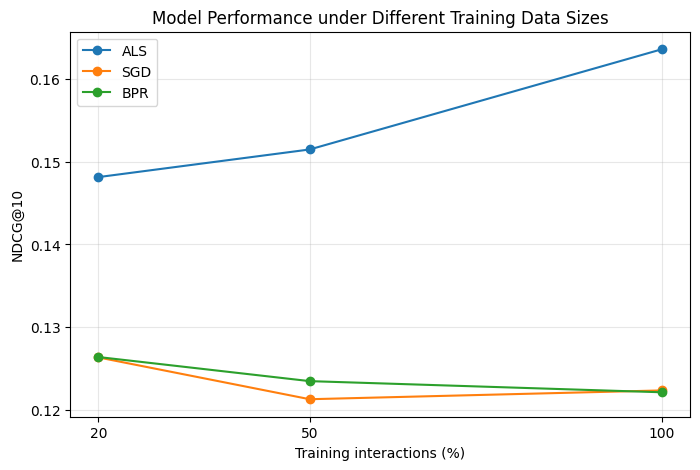

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for model_name in ["ALS", "SGD", "BPR"]:

    model_results = (
        training_fraction_results_df[
            training_fraction_results_df["Model"] == model_name
        ]
        .sort_values("Training fraction", ascending=False)
    )

    plt.plot(
        model_results["Training fraction"] * 100,
        model_results["NDCG@10"],
        marker="o",
        label=model_name
    )

plt.xlabel("Training interactions (%)")
plt.ylabel("NDCG@10")
plt.title("Model Performance under Different Training Data Sizes")
plt.xticks([20, 50, 100])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()